# Why we generally do not use sigmoid or softmax activation function in last layer?
    Why We Often Avoid Them During Training (Numerical Stability)
    
    In frameworks like TensorFlow/Keras and PyTorch, it is standard practice to output raw logits (linear activations without Softmax or Sigmoid) from the final layer and combine them directly with a loss function like BinaryCrossentropy(from_logits=True) or SparseCategoricalCrossentropy(from_logits=True)

    There are two primary reasons for this:

    A. Numerical Underflow and Overflow (The Log-Sum-Exp Trick)
    
    Mathematically, loss functions involve taking the logarithm of probabilities (log(softmax(x))). If you apply Softmax first, extreme logit values can be rounded to 0 or 1 due to computer floating-point limitations. Taking the log(0) results in negative infinity (-inf), leading to NaN (Not a Number) errors that break training.
    By keeping the model output as raw logits and passing them into a combined loss function, the framework uses mathematically stable algebraic shortcuts (like the log-sum-exp trick) to prevent precision loss.

    B. Gradient Saturation
    
    Sigmoid and Softmax functions have flat regions where their derivatives approach zero (e.g., when a sigmoid input is very large or very small, its gradient becomes nearly 0). If you apply these activations in the final layer prematurely, confident incorrect predictions can cause gradient vanishing, halting the learning process.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score,classification_report)

import tensorflow as tf 

In [2]:
RANDOM_STATE = 24
np.random.seed(seed=RANDOM_STATE)
tf.random.set_seed(seed=RANDOM_STATE)

EPOCHS = 100
ALPHA = 0.001 
TEST_SIZE = 0.2

params = { 'legend.fontsize': 'medium',
           'figure.figsize':(15,10),
           'axes.labelsize':'medium',
           'axes.titlesize':'medium',
           'xtick.labelsize': 'medium',
           'ytick.labelsize': 'medium'
}

plt.rcParams.update(params)
CMAP = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

## helper function

In [3]:
physical_devices = tf.config.list_physical_devices('GPU')
if len(physical_devices) > 0:
    tf.config.experimental.set_memory_growth(physical_devices[0],True)

## read wine data set

In [4]:
data_df = pd.read_csv('C:/Users/RAJESH/Desktop/As/Deep_learning/datasets/wine.csv',header=None)
data_df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740,3
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750,3
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835,3
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840,3


In [5]:
data_df.shape

(178, 14)

In [6]:
data_df.describe().T

,count,mean,std,min,25%,50%,75%,max
0,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
1,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
2,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
3,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
4,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
5,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
6,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
7,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
8,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
9,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [7]:
data_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       178 non-null    float64
 1   1       178 non-null    float64
 2   2       178 non-null    float64
 3   3       178 non-null    float64
 4   4       178 non-null    int64  
 5   5       178 non-null    float64
 6   6       178 non-null    float64
 7   7       178 non-null    float64
 8   8       178 non-null    float64
 9   9       178 non-null    float64
 10  10      178 non-null    float64
 11  11      178 non-null    float64
 12  12      178 non-null    int64  
 13  13      178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [8]:
for col in data_df.columns:
    print(f'col: {col},{data_df[col].unique()}')

col: 0,[14.23 13.2  13.16 14.37 13.24 14.2  14.39 14.06 14.83 13.86 14.1  14.12
 13.75 14.75 14.38 13.63 14.3  13.83 14.19 13.64 12.93 13.71 12.85 13.5
 13.05 13.39 13.3  13.87 14.02 13.73 13.58 13.68 13.76 13.51 13.48 13.28
 13.07 14.22 13.56 13.41 13.88 14.21 13.9  13.94 13.82 13.77 13.74 13.29
 13.72 12.37 12.33 12.64 13.67 12.17 13.11 13.34 12.21 12.29 13.49 12.99
 11.96 11.66 13.03 11.84 12.7  12.   12.72 12.08 12.67 12.16 11.65 11.64
 12.69 11.62 12.47 11.81 12.6  12.34 11.82 12.51 12.42 12.25 12.22 11.61
 11.46 12.52 11.76 11.41 11.03 12.77 11.45 11.56 11.87 12.07 12.43 11.79
 12.04 12.86 12.88 12.81 12.53 12.84 13.36 13.52 13.62 12.87 13.32 13.08
 12.79 13.23 12.58 13.17 13.84 12.45 14.34 12.36 13.69 12.96 13.78 13.45
 12.82 13.4  12.2  14.16 13.27 14.13]
col: 1,[1.71 1.78 2.36 1.95 2.59 1.76 1.87 2.15 1.64 1.35 2.16 1.48 1.73 1.81
 1.92 1.57 1.59 3.1  1.63 3.8  1.86 1.6  2.05 1.77 1.72 1.9  1.68 1.5
 1.66 1.83 1.53 1.8  1.65 3.99 3.84 1.89 3.98 4.04 3.59 2.02 1.75 1.67
 1.7  1

In [9]:
data_df.isna().sum().sum()

np.int64(0)

In [10]:
data_df.duplicated().sum()

np.int64(0)

<Axes: >

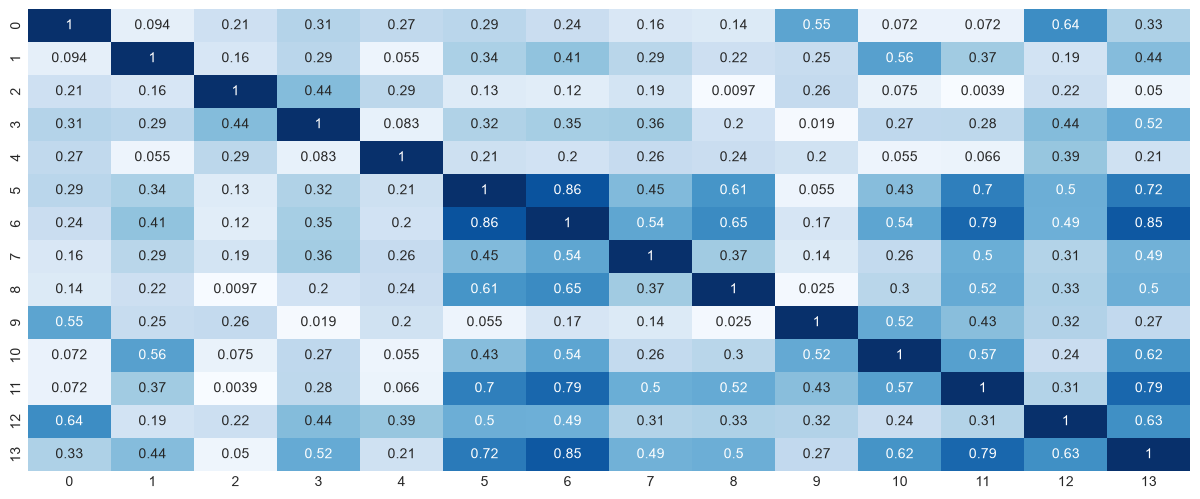

In [11]:
fig,ax = plt.subplots(figsize=(15,6))

sns.heatmap(data=data_df.corr().abs(),
            ax=ax,
            cmap='Blues',
            annot=True,
            fmt='.2g',
            cbar=False)

In [12]:
labels = data_df[data_df.columns[-1]] # last column as label
features_df = data_df.drop(data_df.columns[-1],axis=1)
features_df.shape,labels.shape

((178, 13), (178,))

In [13]:
X_train, X_test, y_train, y_test = train_test_split(features_df, labels, 
                                                    test_size=TEST_SIZE, 
                                                    random_state=RANDOM_STATE, 
                                                    stratify=labels)

print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(142, 13) (36, 13) (142,) (36,)


In [14]:
# Fit_Transform Train / and Only Transform Test

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(142, 13) (36, 13) (142,) (36,)


In [15]:
y_test

array([1, 2, 1, 0, 0, 1, 2, 1, 0, 0, 1, 1, 2, 0, 1, 2, 0, 2, 0, 0, 1, 1,
       1, 0, 0, 2, 1, 1, 1, 1, 2, 0, 2, 2, 0, 2])

## Prepare Model

In [16]:
model = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(X_train.shape[1],)), # Input layer (13 cols, reducing to 3 cols)
        
        tf.keras.layers.Dense(8,activation='relu'), #Hidden layer 
        
        tf.keras.layers.Dense(3) # Output layer
    ]
)

In [17]:
tf.keras.layers.Dense?

Init signature:
tf.keras.layers.Dense(
    units,
    activation=None,
    use_bias=True,
    kernel_initializer='glorot_uniform',
    bias_initializer='zeros',
    kernel_regularizer=None,
    bias_regularizer=None,
    activity_regularizer=None,
    kernel_constraint=None,
    bias_constraint=None,
    lora_rank=None,
    lora_alpha=None,
    quantization_config=None,
    **kwargs,
)
Docstring:     
Just your regular densely-connected NN layer.

`Dense` implements the operation:
`output = activation(dot(input, kernel) + bias)`
where `activation` is the element-wise activation function
passed as the `activation` argument, `kernel` is a weights matrix
created by the layer, and `bias` is a bias vector created by the layer
(only applicable if `use_bias` is `True`). When this layer is
followed by a `BatchNormalization` layer, it is recommended to set
`use_bias=False` as `BatchNormalization` has its own bias term.

Note: If the input to the layer has a rank greater than 2, `Dense`
computes

In [18]:
import sys

sys.float_info.min


2.2250738585072014e-308

In [19]:
sys.float_info.max

1.7976931348623157e+308

In [20]:
np.log(sys.float_info.min)

np.float64(-708.3964185322641)

In [21]:
np.log(sys.float_info.max)

np.float64(709.782712893384)

In [22]:
X_train[:1]

array([[-0.02222104, -0.61751924,  0.85197806,  3.13822833,  2.89556415,
         1.63549206,  0.86441875, -1.2103246 ,  0.59041704, -0.74138556,
         1.52983005,  1.27292302,  0.73966546]])

In [23]:
prediction = model(X_train[:1])
prediction

<tf.Tensor: shape=(1, 3), dtype=float32, numpy=array([[2.9894576, 0.5574291, 2.114473 ]], dtype=float32)>

In [24]:
tf.nn.softmax(prediction)

<tf.Tensor: shape=(1, 3), dtype=float32, numpy=array([[0.6645724 , 0.05838829, 0.27703926]], dtype=float32)>

In [25]:
tf.nn.softmax(prediction).numpy().sum()

np.float32(1.0)

In [26]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 8)                   │             112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 139 (556.00 B)

 Trainable params: 139 (556.00 B)

 Non-trainable params: 0 (0.00 B)

### 13 (cols) * 8 + 8(bias) = 112
### 3(cols)*8 + 3(bias) = 27

In [27]:
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

In [28]:
optimizer = tf.keras.optimizers.Adam(learning_rate=ALPHA)

In [29]:
model.compile(
    optimizer=optimizer,
    loss = loss_fn,
    metrics=['accuracy']
)

In [30]:
history = model.fit(
    X_train,
    y_train,
    validation_data=[X_test,y_test],
    epochs=EPOCHS
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 201ms/step - accuracy: 0.2746 - loss: 1.9167 - val_accuracy: 0.3611 - val_loss: 1.8079
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2817 - loss: 1.8428 - val_accuracy: 0.3889 - val_loss: 1.7370
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.3028 - loss: 1.7720 - val_accuracy: 0.3889 - val_loss: 1.6682
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.3099 - loss: 1.7035 - val_accuracy: 0.3889 - val_loss: 1.6012
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3169 - loss: 1.6376 - val_accuracy: 0.3889 - val_loss: 1.5367
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.3310 - loss: 1.5740 - val_accuracy: 0.4167 - val_loss: 1.4742
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3662 - loss: 1.5126 - val_accuracy: 0.4444 - val_loss: 1.4138
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.3873 - loss: 1.4537 - val_accuracy: 0.4444 - val_loss

In [31]:
loss_df = pd.DataFrame(history.history)
loss_df

,accuracy,loss,val_accuracy,val_loss
0,0.274648,1.916689,0.361111,1.807897
1,0.281690,1.842776,0.388889,1.737037
2,0.302817,1.771994,0.388889,1.668191
3,0.309859,1.703549,0.388889,1.601206
4,0.316901,1.637551,0.388889,1.536703
...,...,...,...,...
95,0.971831,0.157663,0.972222,0.126124
96,0.971831,0.154911,0.972222,0.124261
97,0.978873,0.152227,0.972222,0.122448
98,0.978873,0.149630,0.972222,0.120687


In [32]:
def fn_plot_tf_hist(hist_df):
    
    '''
    Args:
        hist_df: a DataFrame with column names accuracy,loss	val_accuracy	val_loss
    '''
        
    fig, axes = plt.subplots(1,2 , figsize = (15,6))

    # properties  matplotlib.patch.Patch 
    props = dict(boxstyle='round', facecolor='aqua', alpha=0.4)
    facecolor = 'cyan'
    fontsize=12
    CMAP = plt.cm.coolwarm
    # Get columns by index to eliminate any column naming error
    y1 = hist_df.columns[0]
    y2 = hist_df.columns[1]
    y3 = hist_df.columns[2]
    y4 = hist_df.columns[3]

    # Where was min loss on test set
    best = hist_df[hist_df[y4] == hist_df[y4].min()]
    
    ax = axes[0]

    hist_df.plot(y = [y2,y4], ax = ax, colormap=CMAP)

    # little beautification
    txtFmt = "Loss: \n  train: {:6.4f}\n   test: {:6.4f}"
    txtstr = txtFmt.format(hist_df.iloc[-1][y2],
                           hist_df.iloc[-1][y4]) #text to plot
    
    # place a text box in upper middle in axes coords
    ax.text(0.3, 0.95, txtstr, transform=ax.transAxes, fontsize=fontsize,
            verticalalignment='top', bbox=props)
    
    # calculate offset for arrow
    y_min = min(hist_df[y2].min(), hist_df[y4].min())
    y_max = max(hist_df[y2].max(), hist_df[y4].max())
    offset = (y_max-y_min)/10.0
    
    best_idx = best.index.to_numpy()[0]  # Extract first (and only) element as scalar
    best_value = best[y4].to_numpy()[0]   # Extract scalar value
    
    # Mark arrow at lowest
    ax.annotate(f'Min: {best_value:6.4f}', # text to print
                xy=(best_idx, best_value), # Arrow start
                xytext=(best_idx, best_value + offset), # location of text 
                fontsize=fontsize, va='bottom', ha='right',bbox=props, # beautification of text
                arrowprops=dict(facecolor=facecolor, shrink=0.05)) # arrow
    
    # Draw vertical line at best value
    ax.axvline(x = best_idx, color = 'green', linestyle='-.', lw = 3)

    ax.set_xlabel("Epochs")
    ax.set_ylabel(y2.capitalize())
    ax.set_title('Loss Curve')
    ax.grid(True)
    ax.legend(loc = 'upper left') # model legend to upper left
    
    ax = axes[1]

    hist_df.plot( y = [y1, y3], ax = ax, colormap=CMAP)
    
    # little beautification
    txtFmt = "Accuracy: \n  train: {:6.4f}\n  test:  {:6.4f}"
    txtstr = txtFmt.format(hist_df.iloc[-1][y1],
                           hist_df.iloc[-1][y3]) #text to plot

    # place a text box in upper middle in axes coords
    ax.text(0.3, 0.2, txtstr, transform=ax.transAxes, fontsize=fontsize,
            verticalalignment='top', bbox=props)

    # calculate offset for arroe
    y_min = min(hist_df[y1].min(), hist_df[y3].min())
    y_max = max(hist_df[y1].max(), hist_df[y3].max())
    offset = (y_max-y_min)/10.0

    best_value = best[y3].to_numpy()[0]   # Extract scalar value
    # Mark arrow at lowest
    ax.annotate(f'Best: {best_value:6.4f}', # text to print
                xy=(best_idx, best_value), # Arrow start
                xytext=(best_idx, best_value-offset), # location of text 
                fontsize=fontsize, va='bottom', ha='right',bbox=props, # beautification of text
                arrowprops=dict(facecolor=facecolor, shrink=0.05)) # arrow
    
    
    # Draw vertical line at best value
    ax.axvline(x = best_idx, color = 'green', linestyle='-.', lw = 3)

    ax.set_xlabel("Epochs")
    ax.set_ylabel(y1.capitalize())
    ax.set_title('Accuracy Curve')
    ax.grid(True)
    ax.legend(loc = 'lower left')
    
    plt.tight_layout()
    plt.show()

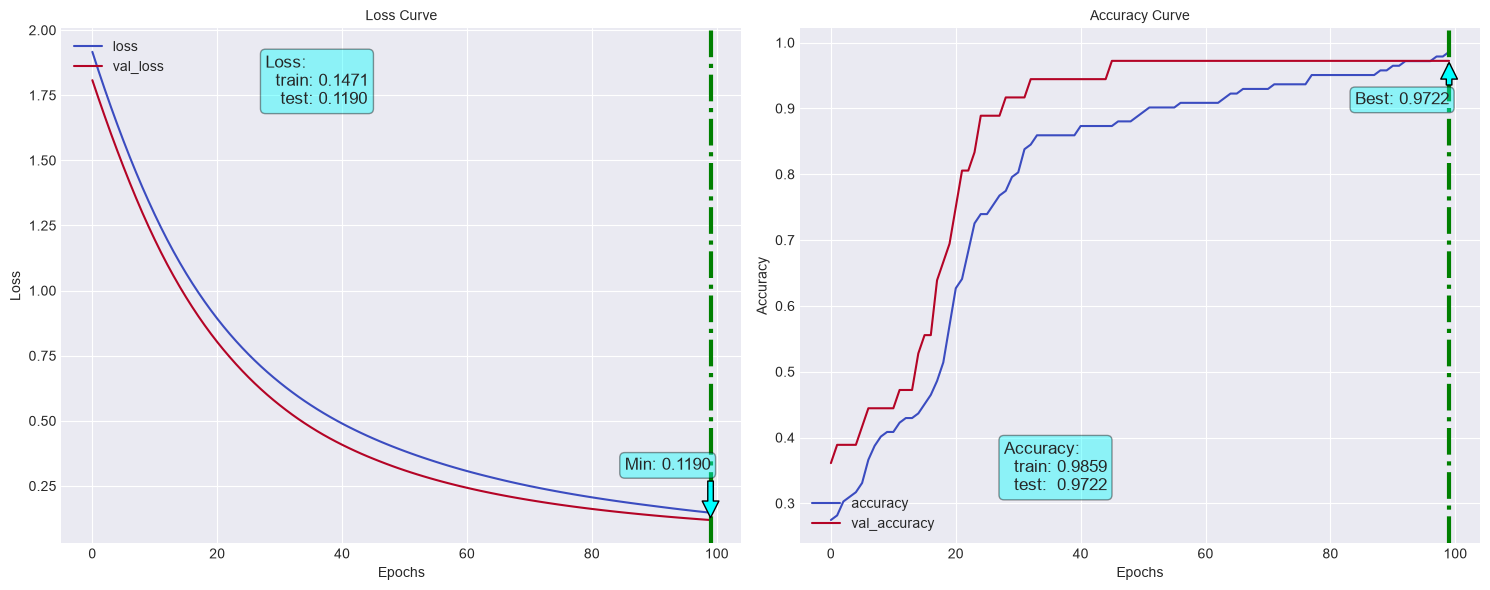

In [33]:
fn_plot_tf_hist(loss_df)

## Train Data

In [34]:
model.evaluate(X_train,y_train,verbose=2)

5/5 - 0s - 12ms/step - accuracy: 0.9859 - loss: 0.1454


[0.14544998109340668, 0.98591548204422]

In [35]:
y_pred = model.predict(X_train)
f_score = f1_score(y_true=y_train,y_pred=y_pred.argmax(axis=1),average='weighted')
accuracy_score(y_train,y_pred.argmax(axis=1))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


0.9859154929577465

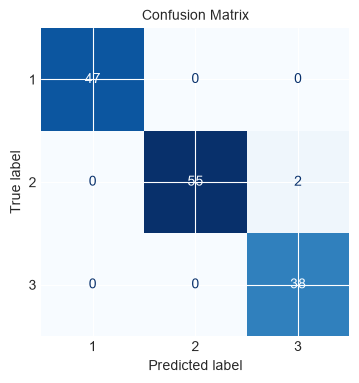

In [36]:
cm = confusion_matrix(y_train, y_pred.argmax(axis=1))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1,2,3])

fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax, cmap=plt.cm.Blues, colorbar=False)  # Pass ax=ax to prevent overlapping plots
plt.title("Confusion Matrix")
plt.show()

## Test Data

In [37]:
y_pred = model.predict(X_test)
f_score = f1_score(y_true=y_test,y_pred=y_pred.argmax(axis=1),average='weighted')
accuracy_score(y_test,y_pred.argmax(axis=1))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


0.9722222222222222

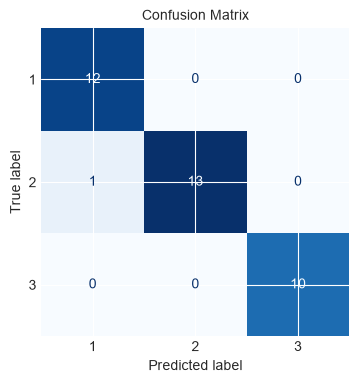

In [38]:
cm = confusion_matrix(y_test, y_pred.argmax(axis=1))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1,2,3])

fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax, cmap=plt.cm.Blues, colorbar=False)  # Pass ax=ax to prevent overlapping plots
plt.title("Confusion Matrix")
plt.show()